In [10]:
import numpy as np
from random_mps import (produce_a_random_mps,produce_a_random_mps_eigenvalues_in_a_disk)
import timeit

In [7]:
# Pauli-Z matrix
Z = np.array([[1, 0], [0, -1]])
I = np.eye(2)

def build_transfer_matrix(A, Op):
    """
    Builds the transfer matrix for a single site.
    A: tensor of shape (d, D_left, D_right)
    O: operator of shape (d, d)
    """
    d, Dl, Dr = A.shape
    T = np.zeros((Dl * Dl, Dr * Dr), dtype=np.complex128)
    for s in range(d):
        for sp in range(d):
            A_s = A[s]             # shape (Dl, Dr)
            A_sp_conj = np.conj(A[sp])  # shape (Dl, Dr)
            coeff = Op[sp, s]
            if coeff != 0: 
                kron = np.kron(A_s, A_sp_conj)  # Kronecker product of two arrays. shape (Dl*Dl, Dr*Dr)
                T += coeff * kron
    return T  # shape (Dl^2, Dr^2)

def compute_C_zz(list_A, i, j):
    """
    Compute C^{zz}(i,j) = <psi|Z_i Z_j|psi>
    list_A: list of tensors (d, D_left, D_right)
    """
    L = len(list_A)
    assert 0 <= i < j < L

    env = np.array([[1.0]], dtype=np.complex128)  # scalar identity

    for n in range(0, i):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    T = build_transfer_matrix(list_A[i], Z)
    env = env @ T

    for n in range(i + 1, j):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    T = build_transfer_matrix(list_A[j], Z)
    env = env @ T

    for n in range(j + 1, L):
        T = build_transfer_matrix(list_A[n], I)
        env = env @ T

    return np.trace(env)

def generate_random_MPS(L, D, d=2):
    """
    Generate a random MPS with physical dimension 2, L sites, and bond dimension D.
    Returns a list of tensors with shape (2, D_left, D_right)
    """
    list_M, _, _, _ = produce_a_random_mps(L, d)
    return list_M

def generate_random_MPS_eigenvalues_in_a_disk(L, d, standard_derivation):
    """
    Generate a random MPS with physical dimension d and L sites.
    Returns a list of tensors with shape (2, D_left, D_right)
    """
    list_M, _, _, _ = produce_a_random_mps_eigenvalues_in_a_disk(L, d, standard_derivation)
    return list_M


def average_correlation_matrix(L, D, num_samples):
    """
    Compute averaged C^{zz}(i,j) matrix for all pairs (i, j)
    """
    corr_matrix = np.zeros((L, L))
    for _ in range(num_samples):
        list_M = generate_random_MPS(L, D)
        for i in range(L):
            for j in range(i + 1, L):
                c = compute_C_zz(list_M, i, j).real
                corr_matrix[i, j] += c
                corr_matrix[j, i] += c  # symmetric
    corr_matrix /= num_samples
    return corr_matrix

In [8]:
"""
Code based on the theory from "The density-matrix renormalization group in the age of 
the matrix product states" by Ulrich Schollwöck §4.2.1.
"""

def contract1(A, C, Op=None):
    """
    WRITE WHAT IT DOES.
    A: tensor of shape (d, D_left, D_right)
    C: mtrix of dimension (D_right, D_right)
    O: operator of shape (d, d)
    """
    
    d, Dl, Dr = A.shape
    new_C = np.zeros((Dr, Dr),  dtype=np.complex128)
    if Op is None:
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T  # shape (Dr, Dl)
            new_C += A_s_dagger @ C @ A[s] 
        return new_C
    else: # Apply the operator
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T  # shape (Dr, Dl)
            for sp in range(d):
                new_C +=  Op[s,sp] * A_s_dagger @ C @ A[sp]
        return new_C # shape (Dl, Dl)


def compute_C_zz2(list_A, i, j):
    """
    Compute C^{zz}(i,j) = <psi|Z_i Z_j|psi>
    list_A: list of tensors (d, D_left, D_right)
    """
    L = len(list_A)
    assert 0 <= i < j < L

    C = np.array([[1.0]], dtype=np.complex128)  # scalar identity

    for n in range(0, i):
        C = contract1(list_A[n], C, None)

    C = contract1(list_A[i], C, Z)

    for n in range(i + 1, j):
        C = contract1(list_A[n], C, None)

    C = contract1(list_A[j], C, Z)

    for n in range(j + 1, L):
        C = contract1(list_A[n], C, None)

    return C



def average_correlation_matrix2(L, d, num_samples, standard_derivation=None):
    """
    Compute averaged C^{zz}(i,j) matrix for all pairs (i, j)
    """
    corr_matrix = np.zeros((L, L))
    if standard_derivation is None:
        for _ in range(num_samples):
            list_M = generate_random_MPS(L, d) 
            for i in range(L):
                for j in range(i + 1, L):
                    c = compute_C_zz2(list_M, i, j).real
                    corr_matrix[i, j] += c
                    corr_matrix[j, i] += c  # symmetric
        corr_matrix /= num_samples
        return corr_matrix
    else:
        for _ in range(num_samples):
            list_M = generate_random_MPS_eigenvalues_in_a_disk(L, d, standard_derivation)
            for i in range(L):
                for j in range(i + 1, L):
                    c = compute_C_zz2(list_M, i, j).real
                    corr_matrix[i, j] += c
                    corr_matrix[j, i] += c  # symmetric
        corr_matrix /= num_samples
        return corr_matrix


In [12]:
np.random.seed(3)
#  Example usage:
N = 6
D = 2
num_samples = 1
start = timeit.default_timer()
corr_mat = average_correlation_matrix2(N, D, num_samples, 0.1)
stop = timeit.default_timer()
print(corr_mat)
print('Time: ', stop - start) 

[[ 0.         -0.00673348  0.00889243  0.12282766  0.43347157  0.15750868]
 [-0.00673348  0.         -0.01096775  0.12642049  0.2184112   0.06273759]
 [ 0.00889243 -0.01096775  0.         -0.12861066  0.35713702 -0.35071936]
 [ 0.12282766  0.12642049 -0.12861066  0.          0.01191825 -0.01250111]
 [ 0.43347157  0.2184112   0.35713702  0.01191825  0.         -0.00604108]
 [ 0.15750868  0.06273759 -0.35071936 -0.01250111 -0.00604108  0.        ]]
Time:  1.4871040990110487


/tmp/ipykernel_309627/557788938.py:79: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corr_matrix[i, j] += c
/tmp/ipykernel_309627/557788938.py:80: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  corr_matrix[j, i] += c  # symmetric


In [11]:
np.random.seed(3)
#  Example usage:
N = 8
D = 4
num_samples = 1
start = timeit.default_timer()
corr_mat = average_correlation_matrix(N, D, num_samples)
stop = timeit.default_timer()
print(corr_mat)
print('Time: ', stop - start)  

[[ 0.00000000e+00 -1.02435775e-01 -5.84445693e-02  8.14737962e-02
  -1.20545109e-01  1.18452633e-01  3.40018614e-02  1.79258079e-02]
 [-1.02435775e-01  0.00000000e+00 -1.13132580e-01  6.74032112e-02
   1.92088928e-01  3.75669327e-02  1.12611018e-02 -1.99332521e-04]
 [-5.84445693e-02 -1.13132580e-01  0.00000000e+00 -2.04236016e-01
   6.54298927e-02  6.92815166e-02  1.50113494e-01 -3.94927651e-02]
 [ 8.14737962e-02  6.74032112e-02 -2.04236016e-01  0.00000000e+00
  -6.65371119e-02 -1.82364662e-01  9.33384657e-04  8.57372250e-02]
 [-1.20545109e-01  1.92088928e-01  6.54298927e-02 -6.65371119e-02
   0.00000000e+00  2.82958152e-02 -4.40681254e-02 -3.70543916e-02]
 [ 1.18452633e-01  3.75669327e-02  6.92815166e-02 -1.82364662e-01
   2.82958152e-02  0.00000000e+00 -1.11714691e-01  2.20449042e-01]
 [ 3.40018614e-02  1.12611018e-02  1.50113494e-01  9.33384657e-04
  -4.40681254e-02 -1.11714691e-01  0.00000000e+00 -2.42448184e-01]
 [ 1.79258079e-02 -1.99332521e-04 -3.94927651e-02  8.57372250e-02
  -

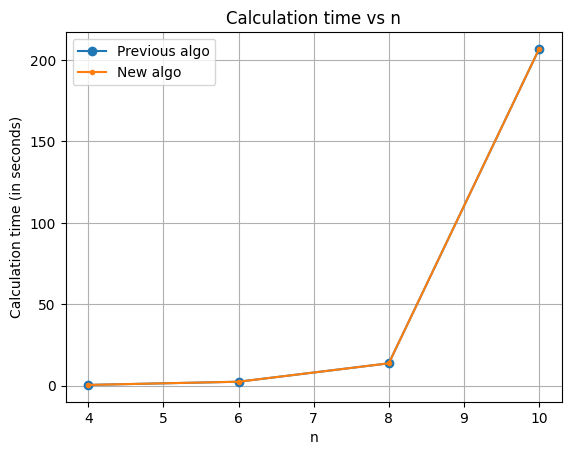

In [15]:
import matplotlib.pyplot as plt

n_list = np.array([4,6,8,10])
time_algo_previous = np.array([0.4824, 2.4443, 13.7511, 206.8611])
time_algo_new = np.array([0.4872, 2.5865, 13.6689, 205.2621])
plt.plot(n_list, time_algo_previous, marker='o', label="Previous algo")
plt.plot(n_list, time_algo_new, marker='.', label="New algo")
plt.xlabel('n')
plt.ylabel('Calculation time (in seconds)')
plt.title('Calculation time vs n')
plt.grid(True)
plt.legend()
plt.show()

In [1]:
import numpy as np
from random_mps import produce_a_random_mps

# Pauli-Z matrix
Z = np.array([[1, 0], [0, -1]])

def contract1(A, C, Op=None):
    d, Dl, Dr = A.shape
    new_C = np.zeros((Dr, Dr), dtype=np.complex128)
    if Op is None:
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T
            new_C += A_s_dagger @ C @ A[s]
    else:
        for s in range(d):
            A_s = A[s]
            A_s_dagger = A_s.conj().T
            for sp in range(d):
                new_C += Op[s, sp] * A_s_dagger @ C @ A[sp]
    return new_C

def compute_expectation(list_A, i, Op):
    """Compute ⟨ψ| Op_i |ψ⟩"""
    L = len(list_A)
    C = np.array([[1.0]], dtype=np.complex128)
    for n in range(0, i):
        C = contract1(list_A[n], C, None)
    C = contract1(list_A[i], C, Op)
    for n in range(i + 1, L):
        C = contract1(list_A[n], C, None)
    return np.trace(C).real

def compute_C_zz_connected_cached(list_A, i, j, cache):
    """
    Compute connected ⟨σ^z_i σ^z_j⟩ - ⟨σ^z_i⟩⟨σ^z_j⟩ using cache for ⟨σ^z_k⟩
    """
    if i not in cache:
        cache[i] = compute_expectation(list_A, i, Z)
    if j not in cache:
        cache[j] = compute_expectation(list_A, j, Z)

    exp_i = cache[i]
    exp_j = cache[j]

    # Two-point function ⟨σ^z_i σ^z_j⟩
    L = len(list_A)
    C = np.array([[1.0]], dtype=np.complex128)
    for n in range(0, i):
        C = contract1(list_A[n], C, None)
    C = contract1(list_A[i], C, Z)
    for n in range(i + 1, j):
        C = contract1(list_A[n], C, None)
    C = contract1(list_A[j], C, Z)
    for n in range(j + 1, L):
        C = contract1(list_A[n], C, None)

    exp_ij = np.trace(C).real
    return exp_ij - exp_i * exp_j

def generate_random_MPS(L, d=2):
    list_M, _, _, _ = produce_a_random_mps(L, d)
    return list_M

def average_connected_C_zz(L, d, num_samples):
    """
    Compute averaged connected C^{zz}(i,j) matrix for all i < j
    """
    corr_matrix = np.zeros((L, L))
    for _ in range(num_samples):
        list_M = generate_random_MPS(L, d)
        cache = {}  # Cache of ⟨σ^z_i⟩
        for i in range(L):
            for j in range(i + 1, L):
                c = compute_C_zz_connected_cached(list_M, i, j, cache)
                corr_matrix[i, j] += c
                corr_matrix[j, i] += c
    corr_matrix /= num_samples
    return corr_matrix


In [6]:
np.random.seed(3)
#  Example usage:
N = 6
D = 2
num_samples = 1

corr_mat = average_connected_C_zz(N, D, num_samples)
print(corr_mat)


[[ 0.         -0.0293472   0.06092304 -0.03264468  0.22310543 -0.13442609]
 [-0.0293472   0.          0.12854959 -0.24507494 -0.10112216  0.07811452]
 [ 0.06092304  0.12854959  0.          0.02423514 -0.45412396  0.02065014]
 [-0.03264468 -0.24507494  0.02423514  0.         -0.12024927  0.16201805]
 [ 0.22310543 -0.10112216 -0.45412396 -0.12024927  0.         -0.2516165 ]
 [-0.13442609  0.07811452  0.02065014  0.16201805 -0.2516165   0.        ]]


In [1]:
import numpy as np
from connected_correlation_functions import average_connected_C_zz_uniform, average_connected_C_zz_eigenvalues_in_a_disk, average_connected_C_zz_eigenvalues_gaussian_in_a_disk
import timeit

In [5]:

#  Example usage:
L = 10
n_samples = 10
d = 2 # Dimension of the local Hilbert space. 
standard_deviation = 0.25
all_corr_matrices = np.zeros((n_samples, L, L))
chi_max = 32

for i in range(n_samples):
    corr_mat = average_connected_C_zz_eigenvalues_gaussian_in_a_disk(L, chi_max, standard_deviation, n_samples, d)
    all_corr_matrices[i] = corr_mat


# Convert to a 3D NumPy array: shape (n_samples, N, N)
all_corr_matrices = np.array(all_corr_matrices)
print(all_corr_matrices)
# Save to file
# np.save(f"corr_matrices_N{N}_n_samples{n_samples}_standard_deviation{standard_derivation}.npy", all_corr_matrices)
# np.save(f"corr_matrices_N{N}_n_samples{n_samples}.npy", all_corr_matrices)

Determining Vidal-representation of MPS tensor M@0, dim(M_0) = 1 x 2
Determining Vidal-representation of MPS tensor M@1, dim(M_1) = 2 x 4
Determining Vidal-representation of MPS tensor M@2, dim(M_2) = 4 x 8
Determining Vidal-representation of MPS tensor M@3, dim(M_3) = 8 x 16
Determining Vidal-representation of MPS tensor M@4, dim(M_4) = 16 x 32
Determining Vidal-representation of MPS tensor M@5, dim(M_5) = 32 x 16
Determining Vidal-representation of MPS tensor M@6, dim(M_6) = 16 x 8
Determining Vidal-representation of MPS tensor M@7, dim(M_7) = 8 x 4
Determining Vidal-representation of MPS tensor M@8, dim(M_8) = 4 x 2
Determining Vidal-representation of MPS tensor M@9, dim(M_9) = 2 x 1
Determining Vidal-representation of MPS tensor M@0, dim(M_0) = 1 x 2
Determining Vidal-representation of MPS tensor M@1, dim(M_1) = 2 x 4
Determining Vidal-representation of MPS tensor M@2, dim(M_2) = 4 x 8
Determining Vidal-representation of MPS tensor M@3, dim(M_3) = 8 x 16
Determining Vidal-represent